# Интеллектуальный анализ данных, БИ

## НИУ ВШЭ, 2025-26 учебный год

## Групповой проект. Machine Learning

## 1. Импорты

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 2. Загрузка датасета после EDA

Подставляем сюда наш датасет, уже очищенный на этапе EDA (фильтры по скорости, удаление
пропусков и выбросов - всё это сделано раньше). Ожидаем таблицу поездок со столбцами:
идентификатор клиента `party_rk`, время начала/конца поездки, дистанция, длительность,
цена, стоимость минуты и активации, модель транспорта и социально-демографические признаки клиента.

In [2]:
trips = pd.read_csv("ready.csv")
print("Размер датасета:", trips.shape)
trips.head()

Размер датасета: (396749, 24)


,order_rk,party_rk,gender_cd,age,lvn_state_nm,minute_cost,activation_cost,hold_amount,transport_model,distance_km,...,local_book_start_dttm,nominal_price_rub_amt,loyalty_accrual_rub_amt,lvn_state_nm_clean,ride_date,ride_month,ride_dayofweek,ride_hour,is_weekend,duration_min
0,266071307,761067705,M,40,ТЮМЕНСКАЯ ОБЛ,4.99,30.0,300.0,SL,3.690479,...,2024-08-07 11:47:29.325252,134.79,19.48,ТЮМЕНСКАЯ ОБЛАСТЬ,2024-08-07,8,2,11,0,20.500238
1,355113920,614049469,F,30,РОСТОВСКАЯ ОБЛ,8.49,50.0,300.0,SL,1.114912,...,2024-10-17 14:57:24.586000,109.43,40.30,РОСТОВСКАЯ ОБЛАСТЬ,2024-10-17,10,3,14,0,6.913893
2,347424551,757583701,M,28,СВЕРДЛОВСКАЯ ОБЛ,5.99,30.0,300.0,E,1.515612,...,2024-09-19 07:34:59.476000,71.93,10.79,СВЕРДЛОВСКАЯ ОБЛАСТЬ,2024-09-19,9,3,7,0,6.844806
3,351562959,541367366,M,24,Г МОСКВА,8.99,50.0,300.0,SL,0.499411,...,2024-10-04 16:05:13.162000,76.97,7.70,МОСКВА,2024-10-04,10,4,16,0,2.309382
4,258647149,238473615,M,34,Г МОСКВА,6.99,50.0,300.0,SL,2.602028,...,2024-07-10 06:57:43.017125,126.89,25.38,МОСКВА,2024-07-10,7,2,6,0,10.090489


### 2.1 Производные признаки

На очищенных данных считаем признаки, которые понадобятся обеим задачам: длительность поездки,
среднюю скорость, ожидаемую цену (`активация + минута * длительность`) и её отклонение от факта -
`price_residual` (главный сигнал аномалий биллинга).

In [3]:
trips["start_time"] = pd.to_datetime(trips["book_start_dttm"])
trips["end_time"] = pd.to_datetime(trips["book_end_dttm"])

# длительность в минутах и время от брони до старта
trips["duration_minutes"] = (trips["end_time"] - trips["start_time"]).dt.total_seconds() / 60
trips["book_to_start"] = (trips["start_time"] - pd.to_datetime(trips["created_dttm"])).dt.total_seconds()

# средняя скорость и отклонение цены от ожидаемой
trips["average_speed"] = trips["distance_km"] / (trips["duration_minutes"] / 60)
trips["price_expected"] = trips["activation_cost"] + trips["minute_cost"] * trips["duration_minutes"]
trips["price_residual"] = trips["nominal_price_rub_amt"] - trips["price_expected"]

# время суток и день недели
trips["hour"] = trips["start_time"].dt.hour
trips["dow"] = trips["start_time"].dt.dayofweek

trips.head(3)

,order_rk,party_rk,gender_cd,age,lvn_state_nm,minute_cost,activation_cost,hold_amount,transport_model,distance_km,...,duration_min,start_time,end_time,duration_minutes,book_to_start,average_speed,price_expected,price_residual,hour,dow
0,266071307,761067705,M,40,ТЮМЕНСКАЯ ОБЛ,4.99,30.0,300.0,SL,3.690479,...,20.500238,2024-08-07 09:47:29.325252,2024-08-07 10:07:59.339524,20.500238,4.325252,10.801275,132.296187,2.493813,9,2
1,355113920,614049469,F,30,РОСТОВСКАЯ ОБЛ,8.49,50.0,300.0,SL,1.114912,...,6.913893,2024-10-17 14:57:24.586000,2024-10-17 15:04:19.419607,6.913893,4.586000,9.675407,108.698955,0.731045,14,3
2,347424551,757583701,M,28,СВЕРДЛОВСКАЯ ОБЛ,5.99,30.0,300.0,E,1.515612,...,6.844806,2024-09-19 05:34:59.476000,2024-09-19 05:41:50.164372,6.844806,198.476000,13.285504,71.000389,0.929611,5,3


## 3. Задача 1: Прогноз оттока клиентов

### Методология: временной разрез (без утечки)
Чтобы предсказывать отток честно, делим сезон точкой
**1 сентября 2024**:
1. **окно признаков** (апрель–август) - по нему считаем профиль клиента (RFM: Recency, Frequency, Monetary)
2. **окно исхода** (сентябрь–октябрь) - по нему ставим метку

**Отток = клиент был активен до 1 сентября, но не совершил ни одной поездки после**
Признаки берём только из окна признаков, метку из окна исхода.

In [4]:
feat_window = trips[trips["start_time"] < pd.Timestamp("2024-09-01")]    # окно признаков
out_window = trips[trips["start_time"] >= pd.Timestamp("2024-09-01")]    # окно исхода

def make_rfm(g):
    return pd.Series({
        "freq": len(g),
        "monetary_sum": g["nominal_price_rub_amt"].sum(),
        "monetary_mean": g["nominal_price_rub_amt"].mean(),
        "dist_mean": g["distance_km"].mean(),
        "dur_mean": g["duration_minutes"].mean(),
        "recency_days": (pd.Timestamp("2024-09-01") - g["start_time"].max()).days,
        "tenure_days": (g["start_time"].max() - g["start_time"].min()).days,
        "active_days": g["start_time"].dt.normalize().nunique(),
        "avg_hour": g["start_time"].dt.hour.mean(),
        "weekend_share": (g["start_time"].dt.dayofweek >= 5).mean(),
        "minute_cost_mean": g["minute_cost"].mean(),
        "n_transport": g["transport_model"].nunique(),
        "age": g["age"].iloc[0],
        "gender_cd": g["gender_cd"].iloc[0],
    })


clients = feat_window.groupby("party_rk").apply(make_rfm)

#суммарная выручка клиента в окне: если 0 - клиент ушёл
future_revenue = out_window.groupby("party_rk")["nominal_price_rub_amt"].sum()
future_revenue = future_revenue.reindex(clients.index).fillna(0)
clients["churn"] = (future_revenue == 0).astype(int)

print("Клиентов всего:", len(clients))
print("Доля оттока:", clients["churn"].mean())
clients.head(3)

Клиентов всего: 44267
Доля оттока: 0.6734136038132243


/tmp/ipykernel_1516/1131815593.py:23: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  clients = feat_window.groupby("party_rk").apply(make_rfm)


,freq,monetary_sum,monetary_mean,dist_mean,dur_mean,recency_days,tenure_days,active_days,avg_hour,weekend_share,minute_cost_mean,n_transport,age,gender_cd,churn
party_rk,,,,,,,,,,,,,,,
14717,1,604.26,604.2600,3.263743,73.699354,42,0,1,15.0,1.0,7.490,1,43,M,1
15725,2,240.90,120.4500,0.007364,9.108588,2,0,1,10.0,0.0,8.115,1,40,M,0
22290,4,947.09,236.7725,5.058931,22.422491,41,6,2,11.0,1.0,8.140,1,53,M,0


В итоге у нас отток в 67% - Немало, но возможно здесь так же замешана сезонность кикшеринга

### 3.1 Признаки и предобработка

Собираем препроцессор `ColumnTransformer`: числовые признаки масштабируем `StandardScaler`'ом,
категориальные кодируем `OneHotEncoder`'ом. Дополнительно для визуализации используем `PCA` —
снижение размерности

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split

#числовые и категориальные признаки
num_features = ["freq", "monetary_sum", "monetary_mean", "dist_mean", "dur_mean",
                "recency_days", "tenure_days", "active_days", "avg_hour",
                "weekend_share", "minute_cost_mean", "n_transport", "age"]
cat_features = ["gender_cd"]

X = clients[num_features + cat_features]
y = clients["churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
])

print("Обучающая выборка:", X_train.shape[0], "объектов,", X_train.shape[1], "признаков")
print("Тестовая выборка:", X_test.shape[0], "объектов,", X_test.shape[1], "признаков")
X_train.head(3)

Обучающая выборка: 35413 объектов, 14 признаков
Тестовая выборка: 8854 объектов, 14 признаков


,freq,monetary_sum,monetary_mean,dist_mean,dur_mean,recency_days,tenure_days,active_days,avg_hour,weekend_share,minute_cost_mean,n_transport,age,gender_cd
party_rk,,,,,,,,,,,,,,
766040707,1,117.89,117.890,1.750921,10.669560,56,0,1,22.0,1.0,7.99,1,34,F
1000670265,1,559.40,559.400,6.635289,59.318467,69,0,1,6.0,1.0,8.49,1,50,F
1013744190,2,184.77,92.385,2.232559,11.367660,22,0,2,13.5,0.0,4.99,1,27,M


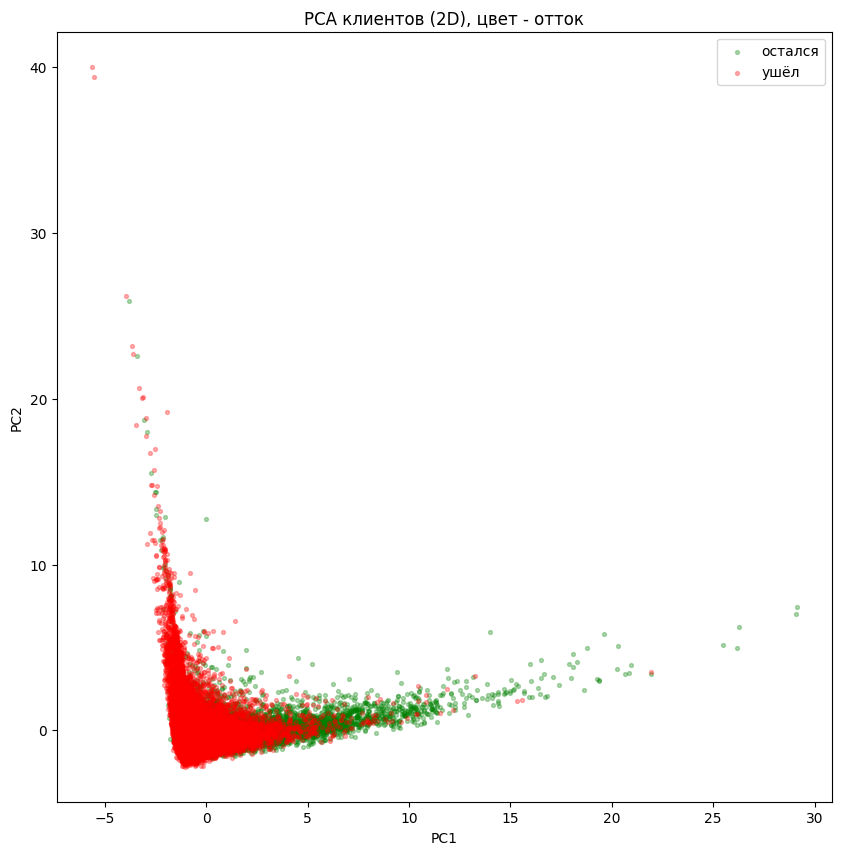

In [7]:
#PCA структуры клиентов (цвет - отток)
from sklearn.decomposition import PCA

X_train_prep = preprocessor.fit_transform(X_train)
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_prep)

plt.figure(figsize=(10, 10))
plt.scatter(X_train_pca[y_train == 0, 0], X_train_pca[y_train == 0, 1], s=8, alpha=0.3, color="green", label="остался")
plt.scatter(X_train_pca[y_train == 1, 0], X_train_pca[y_train == 1, 1], s=8, alpha=0.3, color="red", label="ушёл")
plt.legend()
plt.title("PCA клиентов (2D), цвет - отток")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

### 3.2 Сравнение моделей разной природы

Сравниваем 6 моделей разной природы на одних данных по метрике ROC-AUC (кросс-валидация на трейне):

- **Логистическая регрессия**
- **KNN**
- **SVM**
- **Решающее дерево**
- **Случайный лес**
- **Градиентный бустинг**

Препроцессор (масштабирование + кодирование) зашиваем в `Pipeline`, чтобы внутри кросс-валидации
он обучался только на обучающих фолдах.

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

models = [
    ("Логистическая регрессия", LogisticRegression(max_iter=1000)),
    ("KNN", KNeighborsClassifier(n_neighbors=25)),
    ("SVM", SVC(C=5, gamma="scale")),
    ("Решающее дерево", DecisionTreeClassifier(max_depth=8, random_state=42)),
    ("Случайный лес", RandomForestClassifier(n_estimators=300, random_state=42)),
    ("Градиентный бустинг", GradientBoostingClassifier(random_state=42)),
]

results = []
for i in models:
    pipe = Pipeline([("prep", preprocessor), ("model", i[1])])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc")
    results.append({"Модель": i[0], "ROC-AUC": scores.mean()})
    print(i[0], "ROC-AUC:", scores.mean())

baseline = max(y_train.mean(), 1 - y_train.mean())
print("Бейзлайн по доле преобладающего класса:", baseline)

results = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
results

Логистическая регрессия ROC-AUC: 0.7982003994986463
KNN ROC-AUC: 0.7828862192654773
SVM ROC-AUC: 0.7779027086632103
Решающее дерево ROC-AUC: 0.7832151250347874
Случайный лес ROC-AUC: 0.8016014308608834
Градиентный бустинг ROC-AUC: 0.8117672990479405
Бейзлайн по доле преобладающего класса: 0.6725213904498348


,Модель,ROC-AUC
0,Градиентный бустинг,0.811767
1,Случайный лес,0.801601
2,Логистическая регрессия,0.798200
3,Решающее дерево,0.783215
4,KNN,0.782886
5,SVM,0.777903


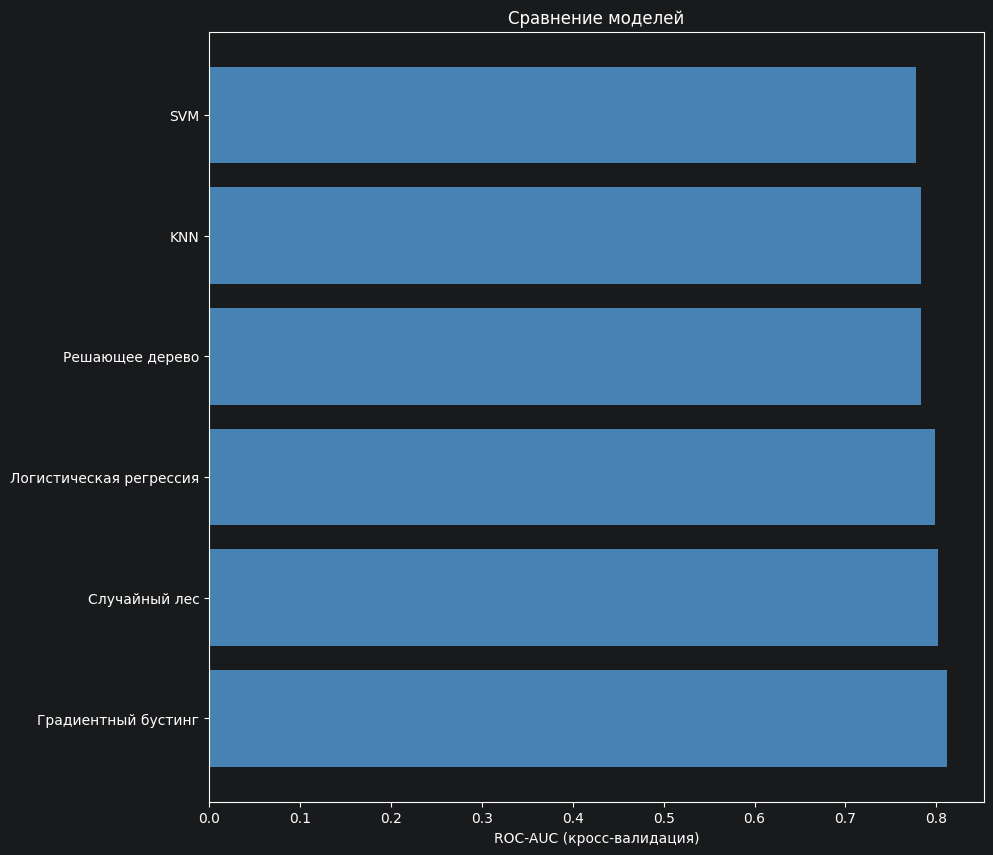

In [ ]:
plt.figure(figsize=(10, 10))
plt.barh(results["Модель"], results["ROC-AUC"], color="steelblue")
plt.xlabel("ROC-AUC (кросс-валидация)")
plt.title("Сравнение моделей")
plt.show()

### 3.3 Подбор гиперпараметров - GridSearchCV

Лучшая по сравнению модель - градиентный бустинг. Подбираем его гиперпараметры перебором по сетке
(`GridSearchCV`) по ROC-AUC.

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.05, 0.1, 0.2],
    "model__max_depth": [2, 3, 4],
}

gb = Pipeline([("prep", preprocessor), ("model", GradientBoostingClassifier(random_state=42))])
grid = GridSearchCV(gb, param_grid, scoring="roc_auc", cv=5)
grid.fit(X_train, y_train)

print("Лучшие параметры:", grid.best_params_)
print("Лучший ROC-AUC", grid.best_score_)

Лучшие параметры: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}
Лучший ROC-AUC 0.8120822455569263


### 3.4 Финальная оценка на отложенной выборке

Финал на тесте
Accuracy = 0.7797605601987803
F1 = 0.8483670295489891
ROC-AUC = 0.8071189196189195

              precision    recall  f1-score   support

     остался       0.73      0.51      0.60      2860
        ушёл       0.79      0.91      0.85      5994

    accuracy                           0.78      8854
   macro avg       0.76      0.71      0.72      8854
weighted avg       0.77      0.78      0.77      8854

Матрица ошибок:
[[1449 1411]
 [ 539 5455]]


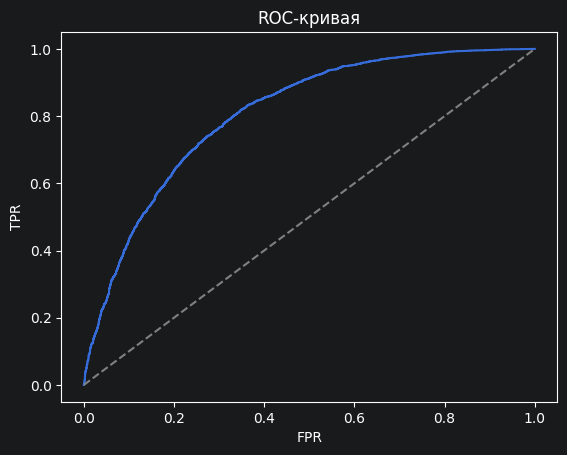

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("Финал на тесте")
print("Accuracy =", accuracy_score(y_test, y_pred))
print("F1 =", f1_score(y_test, y_pred))
print("ROC-AUC =", roc_auc_score(y_test, y_proba))
print()
print(classification_report(y_test, y_pred, target_names=["остался", "ушёл"]))

# матрица ошибок
print("Матрица ошибок:")
print(confusion_matrix(y_test, y_pred))

# ROC-кривая
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], "--", c="grey")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC-кривая")
plt.show()

НУ ЭТО ПРОСТО ПУШЕЧНЫЕ МЕТРИКИ! В ПРОД! МЕДАЛЬ!

### 3.5 Интерпретация — важность признаков

Смотрим, какие признаки сильнее всего влияют на предсказание оттока (`feature_importances_` бустинга).

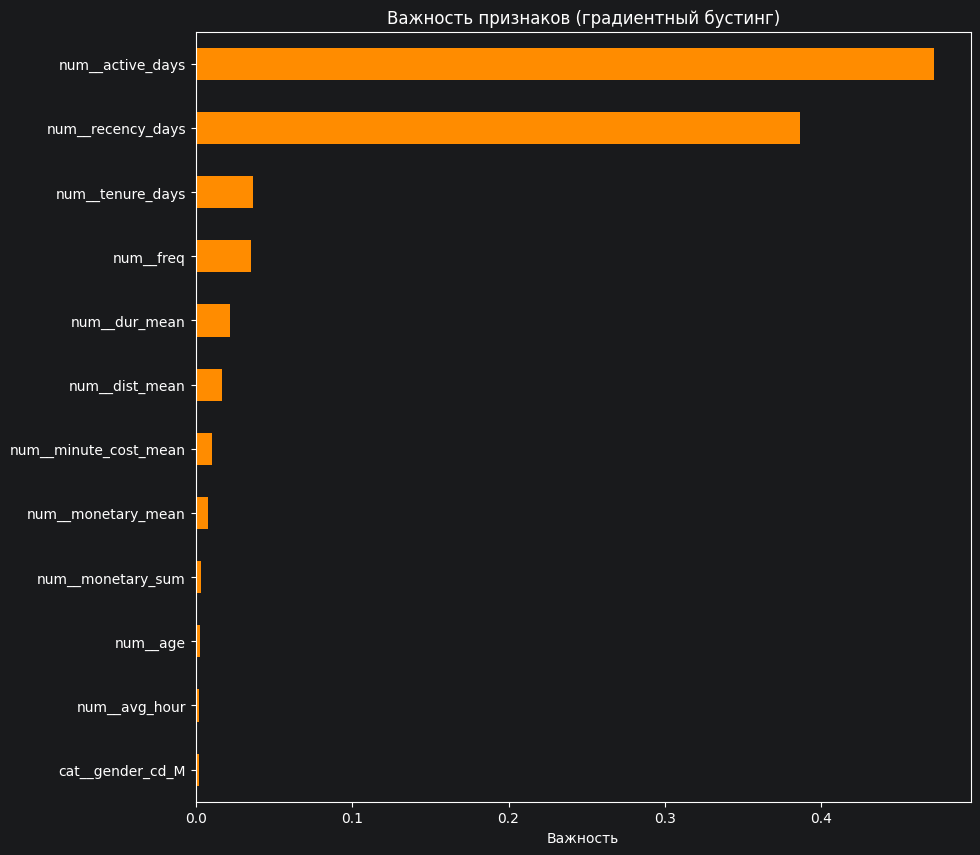

In [ ]:
#важность признаков из бустинга внутри пайплайна
model = best_model.named_steps["model"]
feature_names = best_model.named_steps["prep"].get_feature_names_out()
importances = pd.Series(model.feature_importances_, index=feature_names)
importances = importances.sort_values()

plt.figure(figsize=(10, 10))
importances.tail(12).plot.barh(color="darkorange")
plt.title("Важность признаков (градиентный бустинг)")
plt.xlabel("Важность")
plt.show()

### 3.6 Выводы по задаче 1

- Лучшая модель - **градиентный бустинг** с подбором гиперпараметров
- Главные драйверы оттока по важности признаков - recency (давно не катался), низкая частота
  поездок и короткий tenure: разовые пользователи уходят чаще.
- **Для бизнеса:** берём топ клиентов по предсказанной вероятности оттока (а не всех подряд) и шлём
  им точечные офферы/пуши - это снижает стоимость удержания при том же бюджете.

## 4. Задача 2 - Антифрод: поиск аномальных поездок

Размеченного фрода нет, поэтому это **задача поиска аномалий без учителя**. Признаки поездки масштабируем
и ищем выбросы методами кластеризации. Для ориентира используем простые правила подозрительности
(нереальная скорость, сверхдлинная поездка, слишком большая дистанция)

In [ ]:
from sklearn.preprocessing import StandardScaler
anom = trips.copy()

#лог-преобразование тяжёлых хвостов - в отдельные колонки, оригиналы не портим для сравнения
for c in ["distance_km", "duration_minutes", "average_speed"]:
    anom[c + "_log"] = np.log(anom[c] + 1)

#для поиска аномалий берём логарифмированные признаки
anom_features = ["distance_km_log", "duration_minutes_log", "average_speed_log"]

Xa = StandardScaler().fit_transform(anom[anom_features])

#правила считаем по ОРИГИНАЛЬНЫМ колонкам (они не тронуты)
rule = (anom["average_speed"] > 35) | (anom["duration_minutes"] > 180) | (anom["distance_km"] > 30) | ((anom["distance_km"] == 0) & (anom["duration_minutes"] > 5))
print("Поездок:", len(anom))
print("По правилам подозрительно:", rule.mean(), rule.sum())

Поездок: 396749
По правилам подозрительно: 0.013383776644679634 5310


1 процент аномальных поездок - немного. НО ЭТО ДЕНЬГИ! Так что в рамках антифрода 1% - очень даже весомо

### 4.1 KMeans

Кластеризуем поездки `KMeans`'ом. Аномальными считаем поездки,
которые дальше всего от центра своего кластера - берём верхние 10% по расстоянию.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

#берём подвыборку, чтобы силуэт считался быстро
rng = np.random.RandomState(42)
idx = rng.choice(len(Xa), size=min(5000, len(Xa)), replace=False)
Xs = Xa[idx]

#подбор числа кластеров по силуэту
best_k, best_score = None, -1
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(Xs)
    if len(np.unique(labels)) < 2:   #KMeans схлопнул всё в один кластер - пропускаем
        continue
    score = silhouette_score(Xs, labels)
    print("k =", k, ":", score)
    if score > best_score:
        best_score, best_k = score, k

print("Лучшее число кластеров:", best_k)

k = 2 : 0.36014768283545856
k = 3 : 0.4305286003054527
k = 4 : 0.3503054312830345
k = 5 : 0.35789271541098194
k = 6 : 0.3678110808827627
k = 7 : 0.34009450270764574
Лучшее число кластеров: 3


In [ ]:
km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
km.fit(Xa)

#расстояние до ближайшего центра кластера
dist_to_center = km.transform(Xa).min(axis=1)
threshold = np.quantile(dist_to_center, 1 - 0.1)

anom["anom_score"] = dist_to_center
anom["anomaly"] = (dist_to_center > threshold).astype(int)

print("Помечено аномалий:", anom["anomaly"].sum())
print("Доля аномалий:", anom["anomaly"].mean())
print("Совпадение с правилами (recall):", anom.loc[rule, "anomaly"].mean())

Помечено аномалий: 39675
Доля аномалий: 0.10000025204852438
Совпадение с правилами (recall): 0.8687382297551789


Супер recall - модель хорошо обучилась и готова к проду

### 4.2 DBSCAN - сравнение метода

Тот же масштабированный набор поездок прогоняем через `DBSCAN`. `-1` - выбросы. Сравниваем, насколько две разные по природе кластеризации согласуются между собой и с правилами.

In [ ]:
from sklearn.cluster import DBSCAN

#DBSCAN считаем на подвыборке Xs - на всех поездках он слишком медленный
dbscan = DBSCAN(eps=2, min_samples=10)
db_labels = dbscan.fit_predict(Xs)

db_anom = (db_labels == -1)                  #шум DBSCAN = аномалии
rule_s = rule.values[idx]                    #правила на той же подвыборке
km_anom_s = anom["anomaly"].values[idx]      #флаги KMeans на той же подвыборке

print("Аномалий по DBSCAN:", db_anom.sum())
print("Доля аномалий по DBSCAN:", db_anom.mean())
print("Совпадение DBSCAN с правилами (recall):", (db_anom & rule_s).sum() / max(rule_s.sum(), 1))

#сравнение методов на одной и той же подвыборке
compare = pd.DataFrame({
    "метод": ["KMeans (расстояние)", "DBSCAN (шум)"],
    "доля аномалий": [km_anom_s.mean(), db_anom.mean()],
    "recall к правилам": [(km_anom_s.astype(bool) & rule_s).sum() / max(rule_s.sum(), 1),
                            (db_anom & rule_s).sum() / max(rule_s.sum(), 1)],
})
compare

Аномалий по DBSCAN: 5
Доля аномалий по DBSCAN: 0.001
Совпадение DBSCAN с правилами (recall): 0.07042253521126761


,метод,доля аномалий,recall к правилам
0,KMeans (расстояние),0.1028,0.943662
1,DBSCAN (шум),0.0010,0.070423


А вот DBSCAN выдает печальную картину (да и на больших данных он очень неэффективен, мы, к сожалению, проверяли)

### 4.3 Визуализация и интерпретация

Финальным детектором берём KMeans по расстоянию.
Смотрим распределение скоринга, проекцию PCA, топ-аномалии и оценку выручки под риском.

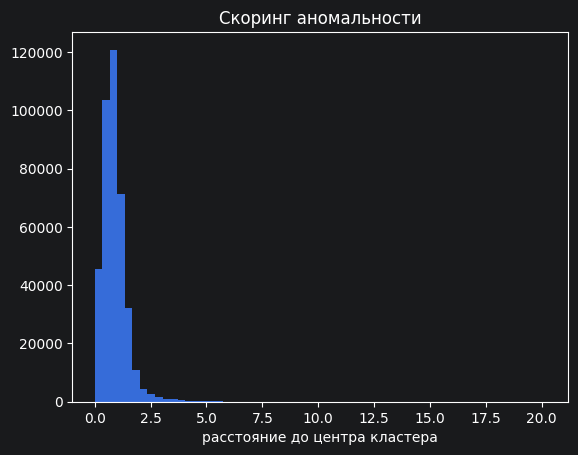

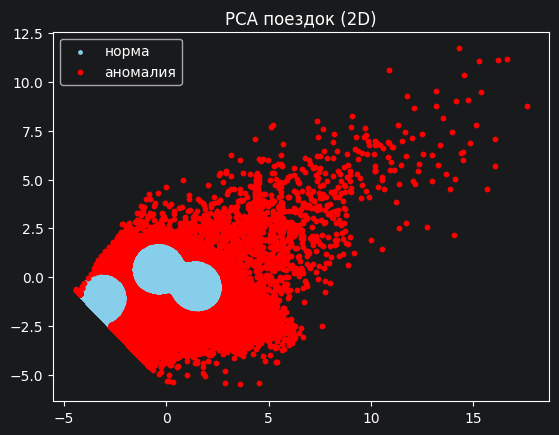

In [ ]:
# распределение скоринга аномальности
plt.hist(anom["anom_score"], bins=60)
plt.title("Скоринг аномальности")
plt.xlabel("расстояние до центра кластера")
plt.show()

# проекция PCA, цвет - аномалия
from sklearn.decomposition import PCA
Xa_pca = PCA(n_components=2, random_state=42).fit_transform(Xa)
mask = anom["anomaly"].values == 1
plt.scatter(Xa_pca[~mask, 0], Xa_pca[~mask, 1], s=6, color="skyblue", label="норма")
plt.scatter(Xa_pca[mask, 0], Xa_pca[mask, 1], s=10, color="red", label="аномалия")
plt.legend()
plt.title("PCA поездок (2D)")
plt.show()

In [ ]:
# топ-10 самых аномальных поездок
top = anom.sort_values("anom_score", ascending=False).head(10)
cols = ["distance_km", "duration_minutes", "average_speed",
        "nominal_price_rub_amt", "price_residual", "book_to_start"]
print("ТОП-10 аномальных поездок:")
print(top[cols].to_string())

# оценка выручки под риском
rev_anom = anom.loc[anom["anomaly"] == 1, "nominal_price_rub_amt"].sum()
rev_all = anom["nominal_price_rub_amt"].sum()
print("Выручка по аномальным поездкам:", rev_anom)
print("Доля от оборота:", rev_anom / rev_all)


# профиль аномалий против нормы
profile = anom.groupby("anomaly")[["distance_km", "duration_minutes",
                                   "average_speed", "price_residual"]].median()
profile.index = ["норма", "аномалия"]
print("Медианы признаков:")
print(profile.to_string())

ТОП-10 аномальных поездок:
         distance_km  duration_minutes  average_speed  nominal_price_rub_amt  price_residual  book_to_start
175173  32742.764788          2.990362  656965.911903                  55.47        0.081827       4.981187
313313  25834.347823          2.743284  565038.524073                  69.59        1.676359       4.260000
11244   56012.640308         16.000711  210038.067806                 109.84       -0.003548       3.297341
149103  14748.053050          2.013574  439458.979738                  66.80       -0.114022       3.811017
78258    7743.818059          0.879438  528324.962434                  56.50        0.783653       5.796790
38639   16092.447582          5.483165  176092.992673                  77.94        4.129515       4.182376
260618   9903.272869          2.481145  239484.721874                  78.74        4.970629       3.576468
300080  22317.776290         24.786192   54024.699615                 262.25        1.815230       5.624000
3

### 4.4 Выводы по задаче 2

- **KMeans по расстоянию выбран как продуктовый детектор:** ловит комбинаторные аномалии, применим на больших данных
- По профилю аномалии отличаются нереальной скоростью, длинными поездками и большим расхождением цены
- **Для бизнеса:** аномальные поездки уходят в очередь ручной проверки антифрод-команды: это покрывает
  заметную долю оборота и снижает прямые потери.